# Additional delivery-delay factors

Explore the estimated delivery window jointly with distance, destination state, and seller count. Use the existing **Train** split only. Late rates use all eligible orders in each group; delay summaries use only actual late orders. These are descriptive checks, not causal tests or predictive importance rankings.

Group boundaries are chosen for readability. State plots require at least 200 orders and 20 late orders; these are display rules, not significance thresholds. Full tables retain all observed states. Outputs are saved in `additional_factor_analysis` and a separate figure subfolder.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/ml_preparation/split_manifest.csv').exists())
TABLES = ROOT / 'outputs/tables/delay_prediction/additional_factor_analysis'
FIGURES = ROOT / 'outputs/figures/delay_prediction/additional_factors'
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
FEATURES = ['distance_km_mean', 'destination_rain_state_mean_mm',
            'origin_rain_state_mean_mm']

In [2]:
columns = ['order_id', 'is_late', 'delivery_delay_days',
           'order_delivered_customer_date', 'order_estimated_delivery_date',
           'estimated_window_days', 'customer_state', 'seller_count', *FEATURES]
data = pd.read_csv(ROOT / 'data/processed/research_data_weather_price_holiday_assume_utc.csv',
                   usecols=columns)
manifest = pd.read_csv(ROOT / 'data/ml_preparation/split_manifest.csv')
assert data.order_id.is_unique and manifest.order_id.is_unique
train_ids = manifest.loc[manifest['split'].eq('train'), ['order_id', 'purchase_time']]
train = train_ids.merge(data, on='order_id', how='left', validate='one_to_one', indicator=True)
assert train['_merge'].eq('both').all()
assert len(train) == 57449 and train.is_late.sum() == 3720
assert train.is_late.isin([0, 1]).all()
actual = pd.to_datetime(train.order_delivered_customer_date)
estimated = pd.to_datetime(train.order_estimated_delivery_date)
purchase = pd.to_datetime(train.purchase_time)
delay = (actual.dt.normalize() - estimated.dt.normalize()).dt.days
assert actual.notna().all() and estimated.notna().all()
assert actual.lt(pd.Timestamp('2018-04-16')).all()
assert purchase.lt(pd.Timestamp('2018-03-02')).all()
assert actual.ge(purchase).all()
np.testing.assert_array_equal(delay.to_numpy(), train.delivery_delay_days.to_numpy())
np.testing.assert_array_equal(delay.gt(0).astype(int), train.is_late.astype(int))
assert train[FEATURES].ge(0).where(train[FEATURES].notna(), True).all().all()
assert np.isfinite(train[FEATURES].stack()).all()
late = train.loc[train.is_late.eq(1)].copy()
audit = pd.DataFrame([{
    'orders': len(train), 'late_orders': len(late),
    'late_rate_pct': 100 * train.is_late.mean(),
    'late_delay_median_days': late.delivery_delay_days.median(),
    'late_delay_mean_days': late.delivery_delay_days.mean(),
    'late_delay_p90_days': late.delivery_delay_days.quantile(.9),
}])
audit.to_csv(TABLES / 'train_audit.csv', index=False)
display(audit.round(3))
coverage = pd.DataFrame([{
    'feature': feature, 'valid_orders': train[feature].notna().sum(),
    'missing_orders': train[feature].isna().sum(),
    'missing_late_orders': train.loc[train[feature].isna(), 'is_late'].sum(),
} for feature in FEATURES])
coverage.to_csv(TABLES / 'feature_coverage.csv', index=False)
display(coverage)

,orders,late_orders,late_rate_pct,late_delay_median_days,late_delay_mean_days,late_delay_p90_days
0,57449,3720,6.475,7.0,10.736,22.0


,feature,valid_orders,missing_orders,missing_late_orders
0,distance_km_mean,57149,300,25.0
1,destination_rain_state_mean_mm,56850,599,46.0
2,origin_rain_state_mean_mm,57332,117,5.0


## 1. Additional feature coverage and summary function

Missing values are excluded only from analyses that require the corresponding feature. The 25th–75th percentile range describes dispersion among late orders. The 90th percentile highlights longer delays. None of these ranges is a confidence interval.

In [3]:

additional = ['estimated_window_days', 'customer_state', 'seller_count']
display(train[additional].isna().sum().rename('missing_orders').to_frame())
train[additional].isna().sum().rename('missing_orders').to_csv(TABLES / 'additional_coverage.csv')

def summarize(frame, keys):
    counts = frame.groupby(keys, observed=True).agg(
        orders=('is_late', 'size'), late_orders=('is_late', 'sum'),
        late_rate_pct=('is_late', lambda x: 100*x.mean()),
        distance_median_km=('distance_km_mean', 'median'),
        window_median_days=('estimated_window_days', 'median'))
    delays = frame.loc[frame.is_late.eq(1)].groupby(keys, observed=True).delivery_delay_days
    severity = delays.agg(delay_median_days='median', delay_mean_days='mean',
        delay_p25_days=lambda x: x.quantile(.25),
        delay_p75_days=lambda x: x.quantile(.75),
        delay_p90_days=lambda x: x.quantile(.9))
    counts['late_orders'] = counts.late_orders.astype(int)
    return counts.join(severity)

train['window_group'] = pd.cut(train.estimated_window_days,
    [-np.inf, 14, 21, 28, np.inf], labels=['≤14', '>14–21', '>21–28', '>28'])
train['distance_group'] = pd.cut(train.distance_km_mean,
    [-np.inf, 300, 600, 1000, np.inf], labels=['≤300', '>300–600', '>600–1000', '>1000'])
train['seller_group'] = pd.cut(train.seller_count,
    [0, 1, 2, np.inf], labels=['1 seller', '2 sellers', '3+ sellers'])


,missing_orders
estimated_window_days,0
customer_state,0
seller_count,0


## 2. Estimated delivery window × distance

Compare delivery windows within each distance band. This reduces some differences in geographic distance but does not fully control for destination, season, or product characteristics. Each heatmap cell shows its sample size; cells with few late orders have unstable severity estimates.

,orders,late_orders,late_rate_pct,distance_median_km,window_median_days,delay_median_days,delay_mean_days,delay_p25_days,delay_p75_days,delay_p90_days
window_group,,,,,,,,,,
≤14,3784,187,4.942,30.681,13.0,5.0,9.636,2.0,8.5,16.0
>14–21,12820,834,6.505,201.615,19.0,6.0,8.853,3.0,12.0,20.0
>21–28,23684,1699,7.174,486.254,25.0,7.0,10.669,3.0,14.0,22.0
>28,17161,1000,5.827,858.928,33.0,7.0,12.625,4.0,14.0,24.0


orders  late_orders  late_rate_pct  \
distance_group window_group                                       
≤300           ≤14             3752          187          4.984   
               >14–21          7828          346          4.420   
               >21–28          4394          183          4.165   
               >28             1436           34          2.368   
>300–600       ≤14               22            0          0.000   
               >14–21          4075          379          9.301   
               >21–28         10828          718          6.631   
               >28             4189          192          4.583   
>600–1000      ≤14                2            0          0.000   
               >14–21           704           79         11.222   
               >21–28          6063          449          7.406   
               >28             4335          236          5.444   
>1000          >14–21           164           28         17.073   
               >21–28          2235          334         14.944   
               >28             7122          530          7.442   

                             distance_median_km  window_median_days  \
distance_group window_group                                           
≤300           ≤14                       30.450                13.0   
               >14–21                    79.341                18.0   
               >21–28                   174.261                24.0   
               >28                      164.637                33.0   
>300–600       ≤14                      375.610                14.0   
               >14–21                   380.669                20.0   
               >21–28                   430.678                24.0   
               >28                      444.915                32.0   
>600–1000      ≤14                      803.379                14.0   
               >14–21                   739.161                21.0   
               >21–28                   776.782                25.0   
               >28                      812.363                32.0   
>1000          >14–21                  1458.783                20.0   
               >21–28                  1409.120                26.0   
               >28                     1824.828                34.0   

                             delay_median_days  delay_mean_days  \
distance_group window_group                                       
≤300           ≤14                         5.0            9.636   
               >14–21                      6.0            8.393   
               >21–28                      6.0            9.880   
               >28                         7.0           11.882   
>300–600       ≤14                         NaN              NaN   
               >14–21                      7.0            9.000   
               >21–28                      8.0           11.035   
               >28                         7.0           10.635   
>600–1000      ≤14                         NaN              NaN   
               >14–21                      7.0            9.987   
               >21–28                      7.0           10.307   
               >28                         7.0           11.373   
>1000          >14–21                      6.5            9.571   
               >21–28                      7.0           10.746   
               >28                         7.0           13.947   

                             delay_p25_days  delay_p75_days  delay_p90_days  
distance_group window_group                                                  
≤300           ≤14                      2.0            8.50            16.0  
               >14–21                   3.0           10.00            18.0  
               >21–28                   2.0           13.00            20.0  
               >28                      4.0           15.25            24.6  
>300–600       ≤14                      NaN             NaN             N

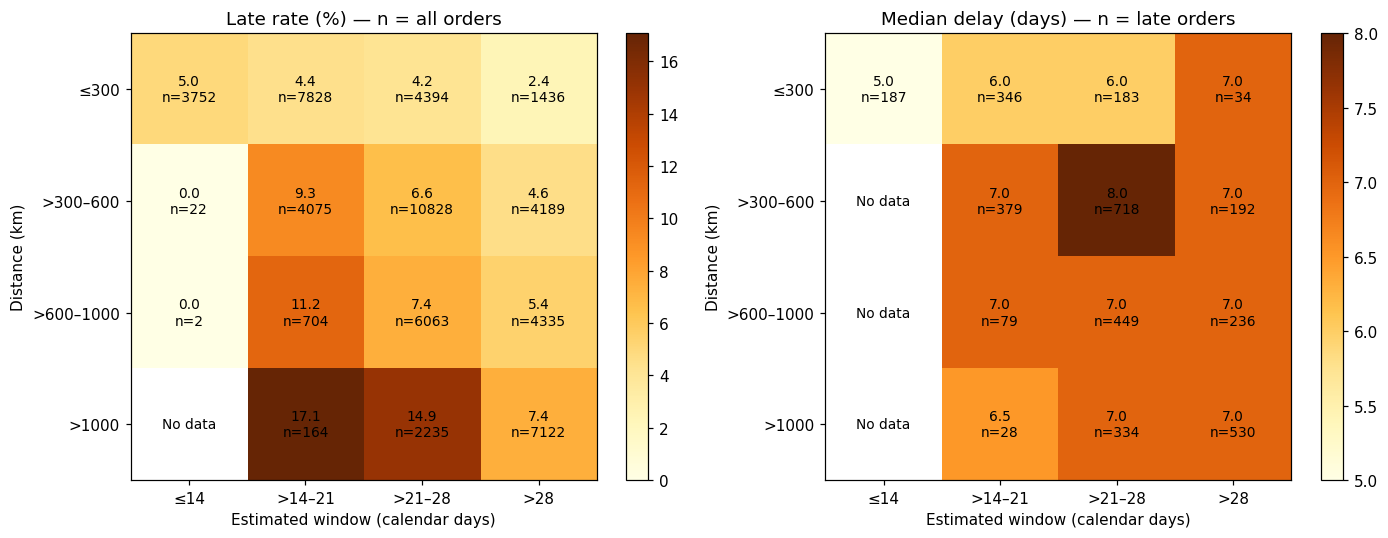

In [4]:

window_summary = summarize(train, 'window_group')
window_summary.to_csv(TABLES / 'estimated_window_groups.csv')
display(window_summary.round(3))
joint = summarize(train, ['distance_group', 'window_group'])
joint.to_csv(TABLES / 'distance_by_estimated_window.csv')
display(joint.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, count, title in zip(axes,
        ['late_rate_pct', 'delay_median_days'], ['orders', 'late_orders'],
        ['Late rate (%) — n = all orders', 'Median delay (days) — n = late orders']):
    values = joint[metric].unstack('window_group')
    counts = joint[count].unstack('window_group').reindex_like(values)
    im = ax.imshow(values.to_numpy(), cmap='YlOrBr', aspect='auto')
    for i in range(len(values)):
        for j in range(len(values.columns)):
            value = values.iloc[i,j]
            label = f'{value:.1f}\nn={counts.iloc[i,j]:.0f}' if pd.notna(value) else 'No data'
            ax.text(j, i, label, ha='center', va='center', fontsize=9)
    ax.set_xticks(range(len(values.columns)), values.columns)
    ax.set_yticks(range(len(values.index)), values.index)
    ax.set_xlabel('Estimated window (calendar days)')
    ax.set_ylabel('Distance (km)')
    ax.set_title(title)
    fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(FIGURES / 'distance_window_heatmaps.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)


## 3. Destination state and seller count

Report group sizes alongside rates and severity. State differences may reflect distance, delivery promises, or other order characteristics. Seller count can overlap with order size and product mix. These tables do not isolate the effect of either variable.

,orders,late_orders,late_rate_pct,distance_median_km,window_median_days,delay_median_days,delay_mean_days,delay_p25_days,delay_p75_days,delay_p90_days
customer_state,,,,,,,,,,
AL,262,63,24.046,1916.049,33.0,7.0,9.365,4.00,12.00,16.0
MA,479,76,15.866,2203.737,32.0,8.0,10.263,4.00,15.25,22.5
SE,224,31,13.839,1721.063,31.0,7.0,20.323,5.00,18.50,23.0
RR,23,3,13.043,3305.545,44.0,6.0,47.667,5.50,69.00,106.8
RJ,7699,979,12.716,397.827,25.0,8.0,11.911,4.00,16.00,25.0
PI,298,36,12.081,2075.445,32.0,6.5,16.583,4.00,13.25,22.5
PB,315,37,11.746,2164.235,35.0,7.0,10.622,3.00,10.00,25.0
CE,801,90,11.236,2290.726,34.0,10.0,13.800,5.00,15.75,25.3
BA,1968,205,10.417,1425.434,31.0,7.0,12.756,3.00,14.00,21.6


,orders,late_orders,late_rate_pct,distance_median_km,window_median_days,delay_median_days,delay_mean_days,delay_p25_days,delay_p75_days,delay_p90_days
seller_group,,,,,,,,,,
1 seller,56814,3712,6.534,453.013,25.0,7.0,10.749,3.00,13.00,22.0
2 sellers,605,8,1.322,437.791,25.0,5.0,4.500,3.75,5.25,6.3
3+ sellers,30,0,0.000,551.074,29.0,NaN,NaN,NaN,NaN,NaN


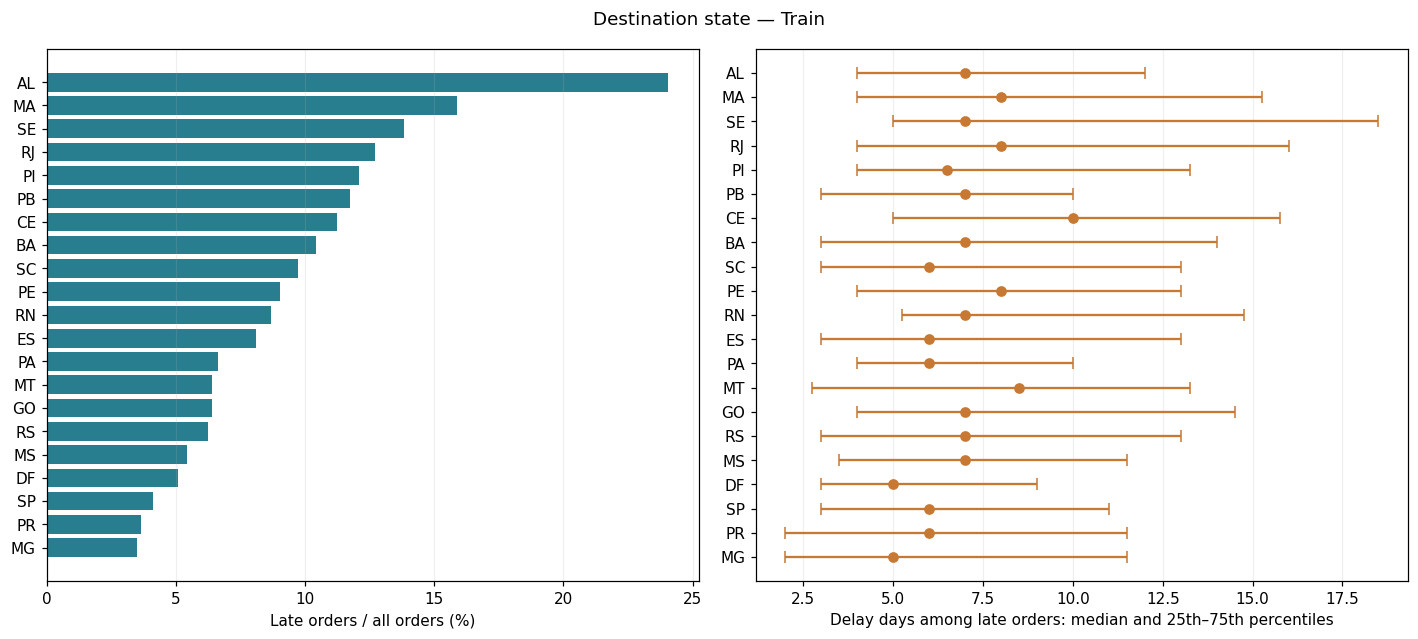

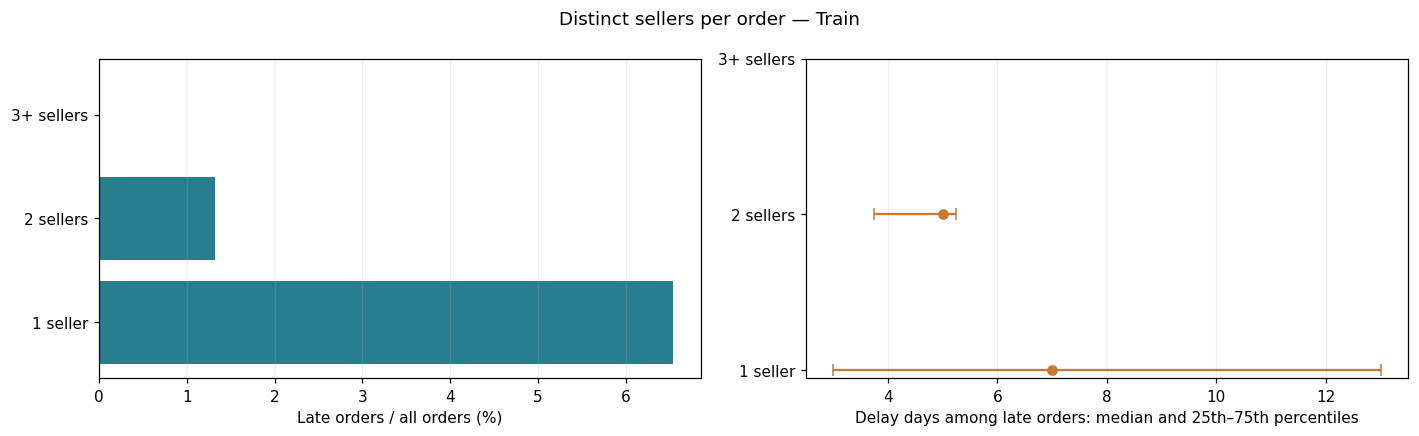

In [5]:

states = summarize(train, 'customer_state')
sellers = summarize(train, 'seller_group')
states.to_csv(TABLES / 'destination_state_summary.csv')
sellers.to_csv(TABLES / 'seller_count_summary.csv')
display(states.sort_values('late_rate_pct', ascending=False).round(3))
display(sellers.round(3))
eligible_states = states.loc[(states.orders >= 200) & (states.late_orders >= 20)]
assert len(eligible_states) > 0
for name, summary, title in [
    ('destination_state', eligible_states.sort_values('late_rate_pct'), 'Destination state'),
    ('seller_count', sellers, 'Distinct sellers per order')]:
    fig, axes = plt.subplots(1, 2, figsize=(13, max(4, .28*len(summary))))
    positions = np.arange(len(summary))
    axes[0].barh(positions, summary.late_rate_pct, color='#287d8e')
    axes[0].set_xlabel('Late orders / all orders (%)')
    median = summary.delay_median_days
    axes[1].errorbar(median, positions,
        xerr=[median-summary.delay_p25_days, summary.delay_p75_days-median],
        fmt='o', capsize=4, color='#c77832')
    axes[1].set_xlabel('Delay days among late orders: median and 25th–75th percentiles')
    for ax in axes:
        ax.set_yticks(positions, summary.index.astype(str))
        ax.grid(axis='x', alpha=.2)
    fig.suptitle(title + ' — Train')
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}_rate_and_severity.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)


## 4. Reading the results

1. Compare late rates and conditional delay severity separately. A group can have a high late rate without especially long delays among its late orders.
2. Within a distance band, inspect whether shorter delivery promises coincide with different rates or severity. Read the sample sizes before interpreting differences.
3. For states and seller counts, inspect both the group medians and dispersion. Broad overlapping ranges limit precise individual predictions from one feature.
4. Treat these patterns as hypotheses for a 21-feature regression model. Compare validation MAE against the Train-median baseline before claiming predictive usefulness.

Only completed outcomes available at the Train cutoff are included. Long-delayed orders still pending at that cutoff may be excluded. Observational grouping does not establish causality. This notebook does not fit a regression model or choose parameters using validation or test outcomes.